# NFIP Flood Insurance Claims: Answering the Research Questions

**DSC 411/511 Semester Project** · Venkat Repaka, Ritik Gaire

This notebook uses the cleaned data and the feature lists from `03_EDA_and_feature_selection_simple.ipynb`.

| RQ | Question | Family | Methods we compare |
|---|---|---|---|
| RQ1 | How much will FEMA pay for the building? | Regression | Ridge regression, Random forest |
| RQ2 | Is this claim high severity (top 20% of building damage)? | Classification | Logistic regression, Decision tree, Random forest |
| RQ3 | Do claims form groups with similar flood risk? | Clustering + PCA | K-means, Hierarchical clustering, K-means on PCA |

**Plan**
0. Setup and the train/test split
1. RQ1: Regression
2. RQ2: Classification
3. RQ3: Clustering and PCA
4. Summary: our three answers, limitations, what we got wrong

---
# Section 0: Setup

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, KFold, StratifiedKFold
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, confusion_matrix)
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, fcluster

SEED = 42
pd.set_option('display.max_columns', 100)

work = pd.read_parquet('outputs/nfip_claims_simple_clean.parquet')
with open('outputs/simple_feature_lists.json') as f:
    FL = json.load(f)

X_all = pd.get_dummies(work[FL['NOMINAL_FEATURES'] + FL['NUMERIC_FEATURES']], columns=FL['NOMINAL_FEATURES'], dtype=int)
work['year'] = work['dateOfLoss'].dt.year
print('Claims:', f'{len(work):,}', '  encoded feature columns:', X_all.shape[1])
print('RQ1 features:', FL['RQ1'])
print('RQ2 features:', FL['RQ2'])
print('RQ3 features:', FL['RQ3'])

Claims: 276,570   encoded feature columns: 96
RQ1 features: ['foundationType_1', 'totalBuildingInsuranceCoverage', 'latitude', 'building_age', 'longitude', 'loss_month', 'report_lag_days', 'postFIRMConstructionIndicator', 'bldg_deductible_usd', 'is_named_event', 'totalContentsInsuranceCoverage', 'elevatedBuildingIndicator', 'numberOfUnits', 'flood_zone_family_AE', 'flood_zone_family_X']
RQ2 features: ['totalBuildingInsuranceCoverage', 'latitude', 'state_group_FL', 'foundationType_1', 'building_age', 'loss_month', 'longitude', 'bldg_deductible_usd', 'report_lag_days', 'is_named_event', 'elevatedBuildingIndicator', 'totalContentsInsuranceCoverage', 'postFIRMConstructionIndicator', 'crsClassCode', 'numberOfUnits']
RQ3 features: ['flood_zone_family', 'foundationType', 'building_age', 'numberOfFloorsInTheInsuredBuilding', 'occupancyType', 'crsClassCode', 'totalBuildingInsuranceCoverage']


## 0.1 How we split the data

We train on the **older years** and test on the **newest years**:

- **Train:** losses in 2020-2023
- **Test:** losses in 2024-2025

**Why not a random split?** Many claims come from the same hurricane. A random split puts claims from the same storm
in both train and test, so the model has already "seen" the storm. That gives a score that is too good.
Testing on later years is like real life: the model must work on **new storms** it has never seen (Helene, Milton).

Inside the training years we also use **5-fold cross validation** to compare models. Random seed = 42 everywhere.

In [2]:
train = work['year'] <= 2023
test = work['year'] >= 2024
print(f"Train (2020-2023): {train.sum():>8,} claims")
print(f"Test  (2024-2025): {test.sum():>8,} claims")
print()
print('Claims per year:')
print(work['year'].value_counts().sort_index())

Train (2020-2023):  161,541 claims
Test  (2024-2025):  115,029 claims

Claims per year:
year
2020     33151
2021     46642
2022     60067
2023     21681
2024    101892
2025     13137
Name: count, dtype: int64


---
# Section 1: RQ1 Regression: Can we predict the dollar amount paid on a building claim?

We use flood-zone, construction, policy and geographic features (the 15 chosen in notebook 03), for claims that were paid.
The question asks for **dollars**, so the main scores are **R² in dollars** and the **error in dollars**.

| Model | Trained on | Why |
|---|---|---|
| Baseline | always the training median | a model must beat this |
| Ridge | log(1 + payment) | simple linear model |
| Random forest | log(1 + payment) | many decision trees |
| **Gradient boosting (Poisson loss)** | **dollars** | trees built one after another, each fixing the last one's errors; Poisson loss fits money (always positive, a few very large values) |

The two log models are turned back into dollars before scoring. R² on the log scale is shown as a side note.

In [3]:
from sklearn.ensemble import HistGradientBoostingRegressor
rows1 = work['is_paid'] == 1
X1 = X_all.loc[rows1, FL['RQ1']].copy()
y1 = work.loc[rows1, 'log_paid_building']
usd1 = work.loc[rows1, 'amountPaidOnBuildingClaim']
tr1, te1 = train[rows1], test[rows1]

# Ridge is a linear model: log the money columns and scale everything (trees do not need this)
X1_lin = X1.copy()
for c in FL['LOG_COLS']:
    if c in X1_lin.columns:
        X1_lin[c] = np.log1p(X1_lin[c])

def boosting():
    return HistGradientBoostingRegressor(loss='poisson', max_iter=400, learning_rate=0.05, random_state=SEED)
print(f'Paid claims: train {tr1.sum():,}  test {te1.sum():,}')
print(f'Features   : {X1.shape[1]}')

Paid claims: train 119,746  test 93,186
Features   : 15


## 1.1 Leakage check

What we checked:
1. None of our features is known only **after** payment or inspection (payment, damage, water depth, values).
2. No feature is suspiciously close to the target (a correlation near 1 would mean it is the answer in disguise).
3. The test years are later than the training years, so the model cannot learn the test storms.

In [4]:
AFTER = ['netBuildingPaymentAmount', 'amountPaidOnBuildingClaim', 'buildingDamageAmount', 'buildingPropertyValue',
         'buildingReplacementCost', 'contentsDamageAmount', 'waterDepth', 'interiorWaterDepth', 'exteriorWaterDepth',
         'causeOfDamage', 'replacementCostBasis']
print('CHECK 1: after-payment / after-inspection columns in the RQ1 features:',
      [c for c in FL['RQ1'] if any(c.startswith(a) for a in AFTER)])
corr = X1[tr1].corrwith(y1[tr1], method='spearman').abs().sort_values(ascending=False)
print(f'CHECK 2: highest correlation of a feature with the target: {corr.index[0]} = {corr.iloc[0]:.2f}')
print(f"CHECK 3: last training date {work.loc[train, 'dateOfLoss'].max().date()}, first test date {work.loc[test, 'dateOfLoss'].min().date()}")

CHECK 1: after-payment / after-inspection columns in the RQ1 features: []


CHECK 2: highest correlation of a feature with the target: foundationType_1 = 0.37
CHECK 3: last training date 2023-12-31, first test date 2024-01-01


## 1.2 Cross validation on the training years

In [5]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
sample = X1[tr1].sample(40000, random_state=SEED).index        # a sample keeps the models fast

ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
forest = RandomForestRegressor(n_estimators=100, min_samples_leaf=20, n_jobs=-1, random_state=SEED)
gb = boosting()

cv_ridge = cross_val_score(ridge, X1_lin.loc[sample], y1.loc[sample], cv=cv, scoring='r2')
cv_forest = cross_val_score(forest, X1.loc[sample], y1.loc[sample], cv=cv, scoring='r2')
cv_gb = cross_val_score(gb, X1.loc[sample], usd1.loc[sample], cv=cv, scoring='r2')
print('5-fold cross validation (training years):')
print(f'   Ridge (log)              R2 log     : {cv_ridge.mean():.3f}  (+/- {cv_ridge.std():.3f})')
print(f'   Random forest (log)      R2 log     : {cv_forest.mean():.3f}  (+/- {cv_forest.std():.3f})')
print(f'   Gradient boosting ($)    R2 dollars : {cv_gb.mean():.3f}  (+/- {cv_gb.std():.3f})')

5-fold cross validation (training years):
   Ridge (log)              R2 log     : 0.250  (+/- 0.006)
   Random forest (log)      R2 log     : 0.416  (+/- 0.008)
   Gradient boosting ($)    R2 dollars : 0.238  (+/- 0.644)


## 1.3 Final test on 2024-2025

We train each model on **all** training years, then predict the test years once.

- **R² dollars:** share of the variation in dollars we explain (1 = perfect, 0 = no better than the average)
- **Median error:** half of the predictions are closer than this, in dollars
- **Mean error:** the average miss, in dollars

In [6]:
def rq1_scores(name, pred_usd):
    t = usd1[te1]
    return {'model': name, 'R2 dollars': r2_score(t, pred_usd), 'median error $': np.median(np.abs(t - pred_usd)),
            'mean error $': mean_absolute_error(t, pred_usd),
            'R2 log (side note)': r2_score(np.log1p(t), np.log1p(np.clip(pred_usd, 0, None)))}

ridge.fit(X1_lin[tr1], y1[tr1])
forest.fit(X1[tr1], y1[tr1])
gb.fit(X1[tr1], usd1[tr1])
pred_forest = forest.predict(X1[te1])
pred_gb = gb.predict(X1[te1])

rq1 = pd.DataFrame([rq1_scores('Baseline (median)', np.full(te1.sum(), usd1[tr1].median())),
                    rq1_scores('Ridge (log -> $)', np.expm1(ridge.predict(X1_lin[te1]))),
                    rq1_scores('Random forest (log -> $)', np.expm1(pred_forest)),
                    rq1_scores('Gradient boosting ($)', pred_gb)]).set_index('model')
rq1.style.format({'R2 dollars': '{:.3f}', 'median error $': '${:,.0f}', 'mean error $': '${:,.0f}', 'R2 log (side note)': '{:.3f}'})

,R2 dollars,median error $,mean error $,R2 log (side note)
model,,,,
Baseline (median),-0.175,"$32,291","$72,976",-0.047
Ridge (log -> $),0.183,"$31,872","$58,873",0.298
Random forest (log -> $),-0.025,"$32,028","$61,962",0.318
Gradient boosting ($),-0.059,"$30,378","$57,036",0.320


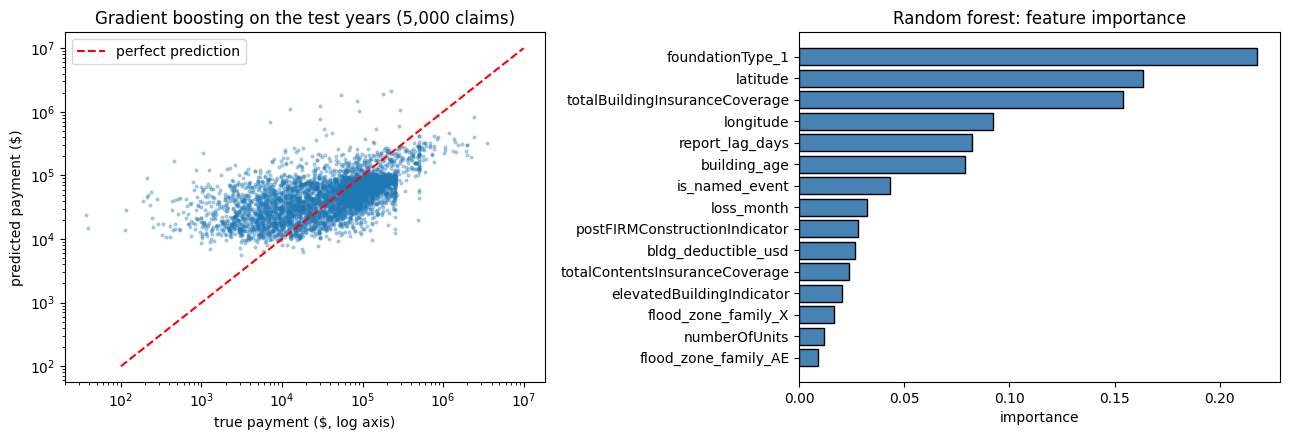

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
idx = np.random.default_rng(SEED).choice(te1.sum(), 5000, replace=False)
ax[0].scatter(usd1[te1].values[idx], pred_gb[idx], s=4, alpha=0.3)
ax[0].plot([100, 1e7], [100, 1e7], 'r--', label='perfect prediction'); ax[0].set_xscale('log'); ax[0].set_yscale('log')
ax[0].set_xlabel('true payment ($, log axis)'); ax[0].set_ylabel('predicted payment ($)')
ax[0].set_title('Gradient boosting on the test years (5,000 claims)'); ax[0].legend()

imp1 = pd.Series(forest.feature_importances_, index=X1.columns).sort_values()
ax[1].barh(imp1.index, imp1.values, color='steelblue', edgecolor='black')
ax[1].set_title('Random forest: feature importance'); ax[1].set_xlabel('importance')
plt.tight_layout(); plt.show()

In [8]:
# Where does the model do well or badly? Error by size of the coverage bought
test_rows = work[rows1 & test].copy()
test_rows['pred_usd'] = pred_gb
test_rows['abs_error'] = (test_rows['amountPaidOnBuildingClaim'] - test_rows['pred_usd']).abs()
test_rows['coverage band'] = pd.cut(test_rows['totalBuildingInsuranceCoverage'], [-1, 100_000, 250_000, 1_000_000, 1e9],
                                    labels=['up to $100k', '$100k-250k', '$250k-1M', 'over $1M'])
print(test_rows.groupby('coverage band', observed=True).agg(claims=('abs_error', 'size'),
                                                           median_payment=('amountPaidOnBuildingClaim', 'median'),
                                                           median_error=('abs_error', 'median')).round(0))

               claims  median_payment  median_error
coverage band                                      
up to $100k     10139         24072.0       15737.0
$100k-250k      73741         68992.0       30974.0
$250k-1M         6059        108431.0       70167.0
over $1M         3247         97382.0      113529.0


## 1.4 Geographic features

Our RQ1 features include **latitude and longitude** (chosen by feature selection in notebook 03), plus the flood zone.
In the regional notebooks, coordinates made predictions on new storms worse. We test that here too,
on our test years (new storms) and, for comparison, on a random 70/30 split of all years.

In [9]:
from sklearn.model_selection import train_test_split
COORDS = ['latitude', 'longitude']
no_coords = [c for c in FL['RQ1'] if c not in COORDS]
ra, rb = train_test_split(X1.index, test_size=0.3, random_state=SEED)
rand_tr, rand_te = X1.index.isin(ra), X1.index.isin(rb)
rows = []
for label, cols in [('with latitude/longitude', FL['RQ1']), ('without latitude/longitude', no_coords)]:
    r = {'features': label}
    for test_name, a, b in [('new storms (2024-25)', tr1.values, te1.values), ('random 70/30', rand_tr, rand_te)]:
        m = boosting().fit(X1.loc[a, cols], usd1[a])
        r[f'R2 dollars, {test_name}'] = r2_score(usd1[b], m.predict(X1.loc[b, cols]))
    rows.append(r)
geo = pd.DataFrame(rows).set_index('features')
geo.round(3)

,"R2 dollars, new storms (2024-25)","R2 dollars, random 70/30"
features,,
with latitude/longitude,-0.059,0.585
without latitude/longitude,0.119,0.536


**Reading the check.** On new storms, latitude and longitude **hurt** the dollar model (R² -0.059 with vs 0.119 without).
On a random split they **help** (0.585 with vs 0.536 without). Coordinates let the model learn *where* past storms caused large payments.
That works when the test claims come from the same storms, and fails when a new storm hits somewhere else.
Geography still enters through the flood zone, whatever the choice for coordinates.

## 1.5 Answer to RQ1

| Model | R² dollars (2024-25) | Median error | Mean error |
|---|---|---|---|
| Baseline (median) | -0.18 | $32,291 | $72,976 |
| **Ridge (log → $)** | **0.18** | $31,872 | $58,873 |
| Random forest (log → $) | -0.03 | $32,028 | $61,962 |
| Gradient boosting ($) | -0.06 | **$30,378** | **$57,036** |
| Gradient boosting ($), no coordinates | 0.12 | - | - |
| *Gradient boosting ($), random 70/30 split* | *0.59* | - | - |

**Answer in plain words.** **On a new storm, only a little.** Using flood-zone, construction, policy and geographic facts,
the best national model (Ridge) explains about **18%** of the dollar differences in building payments on 2024-2025 claims,
and gradient boosting without coordinates about 12%. Half of the predictions still miss by about $30,000 or more.
The errors are largest for big buildings (coverage over $1 million).

**On storms the model has already seen, much better:** with a random 70/30 split of all years, gradient boosting explains about
**59%** of payments in dollars, close to published studies (Saha & Ravela report 0.6-0.8 with a similar split).

So the answer depends on the use: these facts **describe** payments well once a storm's claims are known,
but **predicting** the dollars of a new storm needs information about the storm itself (rainfall, surge height, river levels).

**What this does not show.** Cross validation for gradient boosting jumped a lot between folds (R² 0.24 ± 0.64),
because a few multi-million-dollar claims dominate the fold they land in. The dollar R² is very sensitive to the largest claims.

---
# Section 2: RQ2 Classification: Is this claim high severity?

**Target:** `high_severity` = 1 when building damage is in the top 20% of all claims, else 0.
Claims without a damage figure are not used (we never invent the answer).

**Methods:** Logistic regression, Decision tree, Random forest.

In [10]:
rows2 = work['high_severity'].notna()
X2 = X_all.loc[rows2, FL['RQ2']].copy()
y2 = work.loc[rows2, 'high_severity'].astype(int)
tr2, te2 = train[rows2], test[rows2]
X2_lin = X2.copy()
for c in FL['LOG_COLS']:
    if c in X2_lin.columns:
        X2_lin[c] = np.log1p(X2_lin[c])

print(f'Claims: train {tr2.sum():,}  test {te2.sum():,}')
print(f'High severity share, train: {y2[tr2].mean():.1%}')
print(f'High severity share, test : {y2[te2].mean():.1%}')
print()
print('CHECK: after-inspection columns in the RQ2 features:', [c for c in FL['RQ2'] if any(c.startswith(a) for a in AFTER)])

Claims: train 140,350  test 103,511
High severity share, train: 14.4%
High severity share, test : 27.6%

CHECK: after-inspection columns in the RQ2 features: []


## 2.1 The classes are imbalanced

Only about 1 in 5 training claims is high severity. A model that always says "not severe" would be right
about 80% of the time and still be useless. So:
- we use `class_weight='balanced'`: mistakes on the rare class count more during training;
- we report **precision, recall, F1 and ROC-AUC**, not only accuracy.

| Metric | Question it answers |
|---|---|
| Precision | Of the claims we called severe, how many really were? |
| Recall | Of the really severe claims, how many did we find? |
| F1 | One number that balances precision and recall |
| ROC-AUC | How well the model ranks severe claims above others (0.5 = random) |

In [11]:
always_no = np.zeros(te2.sum(), dtype=int)
print('Baseline "always predict not severe" on the test years:')
print(f'   accuracy : {accuracy_score(y2[te2], always_no):.1%}')
print(f'   recall   : {recall_score(y2[te2], always_no):.1%}   <- finds no severe claim at all')

Baseline "always predict not severe" on the test years:
   accuracy : 72.4%
   recall   : 0.0%   <- finds no severe claim at all


## 2.2 Choosing the depth of the decision tree

A tree that is too deep memorises the training data. We try depths 2 to 14 with 5-fold cross validation.

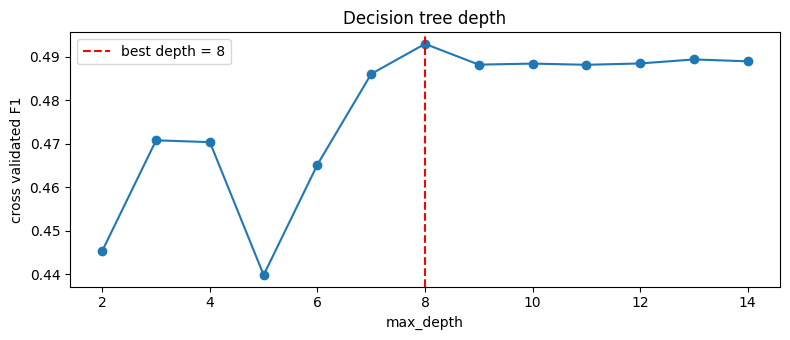

Best depth: 8


In [12]:
cv2 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
sample2 = X2[tr2].sample(40000, random_state=SEED).index
depths = range(2, 15)
depth_scores = [cross_val_score(DecisionTreeClassifier(max_depth=d, class_weight='balanced', random_state=SEED),
                                X2.loc[sample2], y2.loc[sample2], cv=cv2, scoring='f1').mean() for d in depths]
best_depth = list(depths)[int(np.argmax(depth_scores))]
plt.figure(figsize=(8, 3.5))
plt.plot(list(depths), depth_scores, 'o-')
plt.axvline(best_depth, color='red', ls='--', label=f'best depth = {best_depth}')
plt.xlabel('max_depth'); plt.ylabel('cross validated F1'); plt.title('Decision tree depth'); plt.legend()
plt.tight_layout(); plt.show()
print('Best depth:', best_depth)

## 2.3 Cross validation of the three models

In [13]:
logreg = make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=2000))
tree = DecisionTreeClassifier(max_depth=best_depth, class_weight='balanced', random_state=SEED)
forest2 = RandomForestClassifier(n_estimators=100, min_samples_leaf=20, class_weight='balanced', n_jobs=-1, random_state=SEED)

print('5-fold cross validation on the training years:')
for name, model, X in [('Logistic regression', logreg, X2_lin), ('Decision tree', tree, X2), ('Random forest', forest2, X2)]:
    f1 = cross_val_score(model, X.loc[sample2], y2.loc[sample2], cv=cv2, scoring='f1')
    auc = cross_val_score(model, X.loc[sample2], y2.loc[sample2], cv=cv2, scoring='roc_auc')
    print(f'   {name:20s} F1 = {f1.mean():.3f} (+/- {f1.std():.3f})   ROC-AUC = {auc.mean():.3f} (+/- {auc.std():.3f})')

5-fold cross validation on the training years:


   Logistic regression  F1 = 0.433 (+/- 0.009)   ROC-AUC = 0.808 (+/- 0.005)


   Decision tree        F1 = 0.493 (+/- 0.009)   ROC-AUC = 0.837 (+/- 0.011)


   Random forest        F1 = 0.541 (+/- 0.012)   ROC-AUC = 0.878 (+/- 0.005)


## 2.4 Final test on 2024-2025

In [14]:
results2, probs2 = [], {}
for name, model, X in [('Logistic regression', logreg, X2_lin), ('Decision tree', tree, X2), ('Random forest', forest2, X2)]:
    model.fit(X[tr2], y2[tr2])
    pred = model.predict(X[te2]); prob = model.predict_proba(X[te2])[:, 1]
    probs2[name] = (pred, prob)
    results2.append({'model': name, 'accuracy': accuracy_score(y2[te2], pred), 'precision': precision_score(y2[te2], pred),
                     'recall': recall_score(y2[te2], pred), 'F1': f1_score(y2[te2], pred), 'ROC-AUC': roc_auc_score(y2[te2], prob)})
rq2 = pd.DataFrame(results2).set_index('model')
rq2.style.format('{:.3f}')

,accuracy,precision,recall,F1,ROC-AUC
model,,,,,
Logistic regression,0.629,0.419,0.891,0.570,0.788
Decision tree,0.749,0.535,0.685,0.601,0.759
Random forest,0.754,0.562,0.493,0.525,0.796


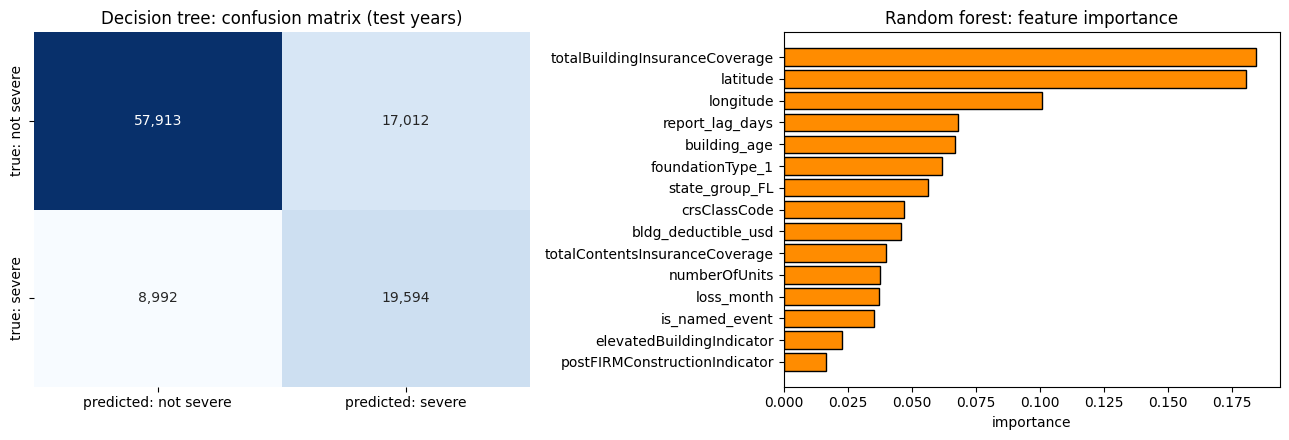

Best model by F1: Decision tree
   severe claims found      : 19,594 of 28,586 (69%)
   false alarms             : 17,012 of 74,925 not-severe claims (23%)


In [15]:
best2 = rq2['F1'].idxmax()
cm = confusion_matrix(y2[te2], probs2[best2][0])
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(cm, annot=True, fmt=',', cmap='Blues', cbar=False, ax=ax[0],
            xticklabels=['predicted: not severe', 'predicted: severe'], yticklabels=['true: not severe', 'true: severe'])
ax[0].set_title(f'{best2}: confusion matrix (test years)')
imp2 = pd.Series(forest2.feature_importances_, index=X2.columns).sort_values()
ax[1].barh(imp2.index, imp2.values, color='darkorange', edgecolor='black')
ax[1].set_title('Random forest: feature importance'); ax[1].set_xlabel('importance')
plt.tight_layout(); plt.show()
tn, fp, fn, tp = cm.ravel()
print(f'Best model by F1: {best2}')
print(f'   severe claims found      : {tp:,} of {tp + fn:,} ({tp / (tp + fn):.0%})')
print(f'   false alarms             : {fp:,} of {tn + fp:,} not-severe claims ({fp / (tn + fp):.0%})')

## 2.5 Answer to RQ2

| Model | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|
| Logistic regression | 0.42 | **0.89** | 0.57 | 0.79 |
| Decision tree (depth 8) | 0.54 | 0.69 | **0.60** | 0.76 |
| Random forest | **0.56** | 0.49 | 0.53 | **0.80** |

**Answer in plain words.** Yes, moderately. The **decision tree** has the best balance (F1 = 0.60).
On 2024-25 it found **69%** of the high-severity claims (19,594 of 28,586) and raised a false alarm on 23% of the others.
Always saying "not severe" would be 72% accurate and find **none**, so accuracy alone is misleading here.

The best model depends on what FEMA wants:
- **Catch almost every severe claim** (and accept many false alarms): logistic regression (recall 0.89).
- **Fewer false alarms:** random forest (precision 0.56). It also ranks claims best (ROC-AUC 0.80), but at the default cut-off it misses half.

The most useful facts were: **coverage**, **location** (latitude, longitude, Florida), **report delay** and **building age**.

**What this does not show.** The random forest was best in cross validation (F1 0.54) but not on the test years.
The share of severe claims almost **doubled** from 14% (train) to 28% (test) because of Helene and Milton.
A model trained on calmer years under-predicts a very bad year.

---
# Section 3: RQ3 Clustering and PCA: Do claims form groups with similar flood risk?

There is **no target**. We group claims by **building and risk facts only**:
flood zone, foundation, building age, number of floors, occupancy, CRS class and coverage.
Payment and damage are **not used to form the groups**. We use them afterwards, to check if the groups mean something.

We use a random sample of 20,000 claims (seed 42), because clustering and silhouette scores are slow on 276k rows.

## 3.0 A check before clustering: two coding systems

Clustering groups claims that *look* similar. If the same building is written with two different codes,
clustering will separate the codes, not the buildings. FEMA changed its rating system in 2021
(legacy → Risk Rating 2.0), and some columns use different codes in each system. We check this first.

In [16]:
print('Occupancy codes by rating system:')
print(pd.crosstab(work['occupancyType'], work['rating_system']))
print()
print('Foundation code 0 by rating system:')
print(pd.crosstab(work['foundationType'] == '0', work['rating_system']).rename(index={True: 'code 0', False: 'other codes'}))

Occupancy codes by rating system:
rating_system  Risk Rating 2.0  legacy
occupancyType                         
1.0                          0   21592
2.0                          0    1370
3.0                          0    1031
4.0                          0     345
6.0                          0    1826
11.0                    188032      40
12.0                      9725       2
13.0                      3970       1
14.0                      6300       4
15.0                     14202    1815
16.0                      8070       0
17.0                        80       0
18.0                     17957       4
19.0                       204       0

Foundation code 0 by rating system:
rating_system   Risk Rating 2.0  legacy
foundationType                         
other codes              248540    1866
code 0                        0   26164


**What the check shows**
- Occupancy codes **1, 2, 3, 4, 6** appear **only** on legacy policies. Risk Rating 2.0 uses **11, 12, 13, 18** for the same building types
  (single family, 2-4 units, 5+ units, non-residential). We translate the old codes into the new ones.
- Foundation code **0** ("not recorded") appears **only** on legacy policies (about 26,000 claims).
  We cannot know their real foundation, so we **leave them out of the clustering**.
  What we give up: about 9% of claims, all from older legacy policies.

Without this fix, one cluster would simply be "legacy policies", and PC1 would mostly measure the coding system.
We saw exactly this in our first run, before we added this check.

In [17]:
OLD_TO_NEW = {1: 11, 2: 12, 3: 13, 4: 18, 6: 18}
w3 = work[work['foundationType'] != '0'].copy()
w3['occupancyType'] = w3['occupancyType'].replace(OLD_TO_NEW)
print(f'Claims available for clustering: {len(w3):,} of {len(work):,}')
print('Occupancy codes left:', sorted(w3['occupancyType'].unique()))

s3 = w3.sample(20000, random_state=SEED)
NOM3 = [c for c in FL['RQ3'] if c in FL['NOMINAL_FEATURES']]
NUM3 = [c for c in FL['RQ3'] if c not in NOM3]
X3 = pd.get_dummies(s3[FL['RQ3']], columns=NOM3, dtype=int)
X3['totalBuildingInsuranceCoverage'] = np.log1p(X3['totalBuildingInsuranceCoverage'])
X3s = StandardScaler().fit_transform(X3)
print('Nominal (one-hot):', NOM3)
print('Numeric          :', NUM3)
print('Columns after encoding:', X3.shape[1])

Claims available for clustering: 250,406 of 276,570
Occupancy codes left: [np.float64(11.0), np.float64(12.0), np.float64(13.0), np.float64(14.0), np.float64(15.0), np.float64(16.0), np.float64(17.0), np.float64(18.0), np.float64(19.0)]


Nominal (one-hot): ['flood_zone_family', 'foundationType', 'numberOfFloorsInTheInsuredBuilding', 'occupancyType']
Numeric          : ['building_age', 'crsClassCode', 'totalBuildingInsuranceCoverage']
Columns after encoding: 31


## 3.1 How many groups? Elbow and silhouette

- **Elbow (inertia):** how tight the groups are. It always falls when k grows; we look for where it stops falling fast.
- **Silhouette:** from -1 to 1. High means each claim is close to its own group and far from the others.

**Rule we decided before looking:** use the k with the highest silhouette between 3 and 8
(k = 2 would only split the data in half, which is too rough to describe risk profiles).

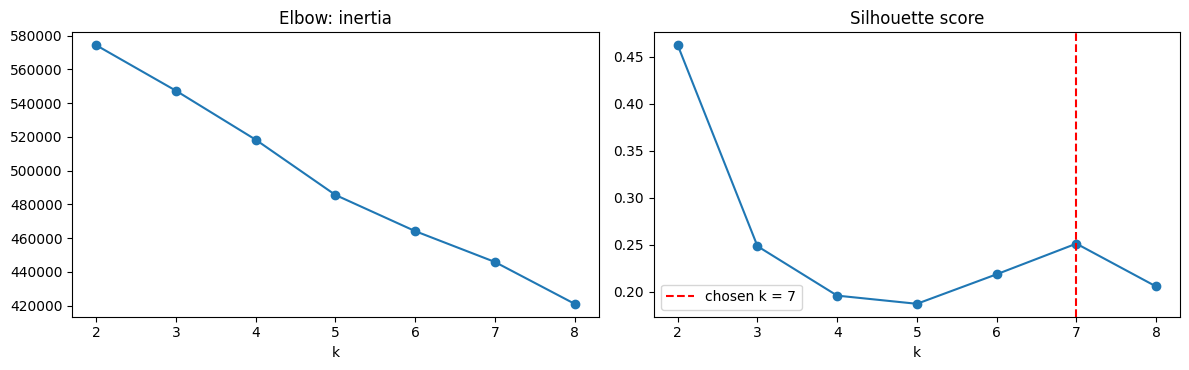

 k  inertia  silhouette
 2 574338.0       0.462
 3 547366.0       0.248
 4 518324.0       0.196
 5 485566.0       0.187
 6 464120.0       0.218
 7 445828.0       0.251
 8 421019.0       0.206
Chosen k: 7


In [18]:
ks = range(2, 9)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X3s)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X3s, km.labels_, sample_size=5000, random_state=SEED))
best_k = list(ks)[1:][int(np.argmax(sil[1:]))]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(list(ks), inertia, 'o-'); ax[0].set_title('Elbow: inertia'); ax[0].set_xlabel('k')
ax[1].plot(list(ks), sil, 'o-'); ax[1].axvline(best_k, color='red', ls='--', label=f'chosen k = {best_k}')
ax[1].set_title('Silhouette score'); ax[1].set_xlabel('k'); ax[1].legend()
plt.tight_layout(); plt.show()
print(pd.DataFrame({'k': list(ks), 'inertia': np.round(inertia, 0), 'silhouette': np.round(sil, 3)}).to_string(index=False))
print('Chosen k:', best_k)

## 3.2 Method 1: K-means, and Method 2: Hierarchical clustering

Hierarchical clustering (Ward linkage) is slow, so we run it on 5,000 of the 20,000 claims and cut the tree into the same
number of groups. **Adjusted Rand Index (ARI)** tells us if the two methods found the same groups
(1 = identical, 0 = no better than random).

In [19]:
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=SEED).fit(X3s)
s3['cluster'] = kmeans.labels_

sub = np.random.default_rng(SEED).choice(len(X3s), 5000, replace=False)
Z = linkage(X3s[sub], method='ward')
hier_labels = fcluster(Z, t=best_k, criterion='maxclust')

print(f"K-means      silhouette (5,000 sample): {silhouette_score(X3s[sub], kmeans.labels_[sub]):.3f}")
print(f"Hierarchical silhouette (5,000 sample): {silhouette_score(X3s[sub], hier_labels):.3f}")
print(f"Agreement between the two methods (ARI): {adjusted_rand_score(kmeans.labels_[sub], hier_labels):.3f}")
print()
print('Claims per K-means cluster:')
print(s3['cluster'].value_counts().sort_index())

K-means      silhouette (5,000 sample): 0.257


Hierarchical silhouette (5,000 sample): 0.192
Agreement between the two methods (ARI): 0.367

Claims per K-means cluster:
cluster
0    1307
1    3547
2    1557
3    1427
4    9723
5     491
6    1948
Name: count, dtype: int64


## 3.3 What is in each cluster? (profile)

We describe each group with the features that formed it.

In [20]:
profile = s3.groupby('cluster').agg(
    claims=('cluster', 'size'),
    median_building_age=('building_age', 'median'),
    median_coverage=('totalBuildingInsuranceCoverage', 'median'),
    median_crs_class=('crsClassCode', 'median'),
    elevated_share=('elevatedBuildingIndicator', 'mean'),
)
profile['top flood zone'] = s3.groupby('cluster')['flood_zone_family'].agg(lambda x: x.value_counts().index[0])
profile['top foundation'] = s3.groupby('cluster')['foundationType'].agg(lambda x: x.value_counts().index[0])
profile['top occupancy'] = s3.groupby('cluster')['occupancyType'].agg(lambda x: x.value_counts().index[0])
profile['top floors code'] = s3.groupby('cluster')['numberOfFloorsInTheInsuredBuilding'].agg(lambda x: x.value_counts().index[0])
profile.round(2)

,claims,median_building_age,median_coverage,median_crs_class,elevated_share,top flood zone,top foundation,top occupancy,top floors code
cluster,,,,,,,,,
0,1307,33.83,250000.0,6.0,0.75,AE,6,11.0,2.0
1,3547,44.27,250000.0,5.0,0.14,AE,1,11.0,2.0
2,1557,58.22,250000.0,7.0,0.44,AE,3,11.0,1.0
3,1427,33.74,250000.0,5.0,0.78,AE,5,11.0,1.0
4,9723,50.74,250000.0,5.0,0.05,AE,1,11.0,1.0
5,491,41.85,70000.0,5.0,0.53,AE,4,14.0,5.0
6,1948,67.17,250000.0,7.0,0.01,AE,2,11.0,2.0


Codes used in the table: foundation 1 = slab, 2 = basement, 3 = crawlspace, 4-6 = elevated (piles, piers, walls), 0 = unknown;
occupancy 11 / 1 = single family, 12 = 2-4 units, 15 = condo building, 18 = non-residential;
floors 1 / 2 / 3 = one / two / three or more, 5 = mobile home.

## 3.4 Do the clusters mean something? Check with outcomes they never saw

         paid_share  median_payment_if_paid  high_severity_share  \
cluster                                                            
0             0.791                11140.06                0.053   
1             0.685                57754.62                0.279   
2             0.814                22993.91                0.150   
3             0.797                10458.50                0.073   
4             0.791                76066.26                0.287   
5             0.829                18118.62                0.035   
6             0.790                14525.73                0.064   

         florida_share  
cluster                 
0                0.539  
1                0.629  
2                0.321  
3                0.607  
4                0.723  
5                0.723  
6                0.041  


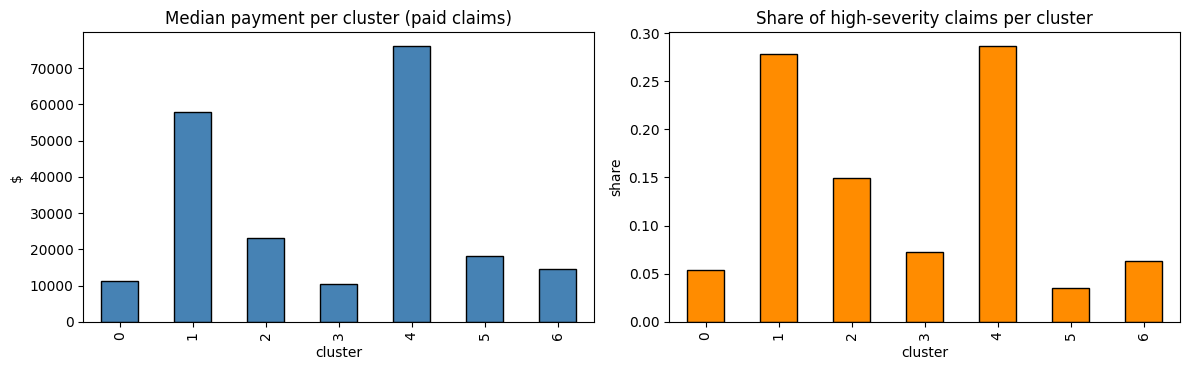

In [21]:
validation = s3.groupby('cluster').agg(
    paid_share=('is_paid', 'mean'),
    median_payment_if_paid=('amountPaidOnBuildingClaim', lambda x: x[x > 0].median()),
    high_severity_share=('high_severity', 'mean'),
    florida_share=('state', lambda x: (x == 'FL').mean()),
)
print(validation.round(3))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
validation['median_payment_if_paid'].plot.bar(ax=ax[0], color='steelblue', edgecolor='black')
ax[0].set_title('Median payment per cluster (paid claims)'); ax[0].set_ylabel('$')
validation['high_severity_share'].plot.bar(ax=ax[1], color='darkorange', edgecolor='black')
ax[1].set_title('Share of high-severity claims per cluster'); ax[1].set_ylabel('share')
plt.tight_layout(); plt.show()

**Naming the clusters** (from the profile table and the outcome table above):

| Cluster | Claims | Name | Median payment | High severity |
|---|---|---|---|---|
| 4 | 9,723 | One-story slab homes (mostly Florida) | $76,066 | 29% |
| 1 | 3,547 | Two-story slab homes | $57,755 | 28% |
| 2 | 1,557 | Older crawlspace homes | $22,994 | 15% |
| 3 | 1,427 | Newer elevated homes on piles | $10,459 | 7% |
| 6 | 1,948 | Old basement homes (outside Florida) | $14,526 | 6% |
| 0 | 1,307 | Newer elevated homes on walls | $11,140 | 5% |
| 5 | 491 | Mobile homes | $18,119 | 3.5% |

**The check:** payment and damage were **never used** to form the clusters, but the clusters still separate them clearly.
Ground-level slab homes have about **28-29%** high-severity claims; elevated homes only **5-7%**.
So the groups are real flood-risk profiles, not random splits.

### How strongly do the clusters separate severity? (Cramér's V)

The table shows *that* the clusters differ. **Cramér's V** says *how much*, in one number from 0 (no link) to 1 (the group decides
the outcome); about 0.1 is small, 0.3 medium and 0.5 large. It comes from the chi-square test on the table cluster × high severity.
To see whether clustering adds anything, we compare it with simpler groupings made from single columns.

In [22]:
from scipy.stats import chi2_contingency

def cramers_v(groups, outcome):
    t = pd.crosstab(groups, outcome)
    chi2, p, dof, _ = chi2_contingency(t.values)
    return np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1))), p

known = s3['high_severity'].notna()
groupings = {'K-means clusters': s3['cluster'],
             'foundation code alone': s3['foundationType'].astype(str),
             'flood zone alone': s3['flood_zone_family'].astype(str),
             'flood zone x foundation pairs': s3['flood_zone_family'].astype(str) + ' | ' + s3['foundationType'].astype(str)}
rows = []
for name, g in groupings.items():
    v, p = cramers_v(g[known], s3.loc[known, 'high_severity'])
    rows.append({'grouping': name, 'groups': g[known].nunique(), "Cramér's V": round(v, 3),
                 'chi-square p': '< 0.001' if p < 0.001 else round(p, 3)})
print(f'Claims with a known severity in the sample: {known.sum():,}')
pd.DataFrame(rows)

Claims with a known severity in the sample: 17,619


,grouping,groups,Cramér's V,chi-square p
0,K-means clusters,7,0.242,< 0.001
1,foundation code alone,6,0.257,< 0.001
2,flood zone alone,8,0.157,< 0.001
3,flood zone x foundation pairs,42,0.321,< 0.001


**Reading the check**
- The K-means clusters are linked to high severity with **V = 0.24** (small to medium), clearly more than chance (p < 0.001).
- But the **foundation code alone** gives almost the same link (**V = 0.26**). The clusters mostly rediscover the foundation type;
  they do not add information about severity beyond it.
- **Flood zone and foundation together** give the strongest link (**V = 0.32**). Part of this is because 42 groups can fit the data
  more closely than 6 or 7, so read it as an upper limit.

## 3.5 PCA: a smaller description of the same data

PCA turns our encoded columns into new columns (components) that capture the most variation first.

**Rule:** keep the smallest number of components that explains **at least 80%** of the variance.

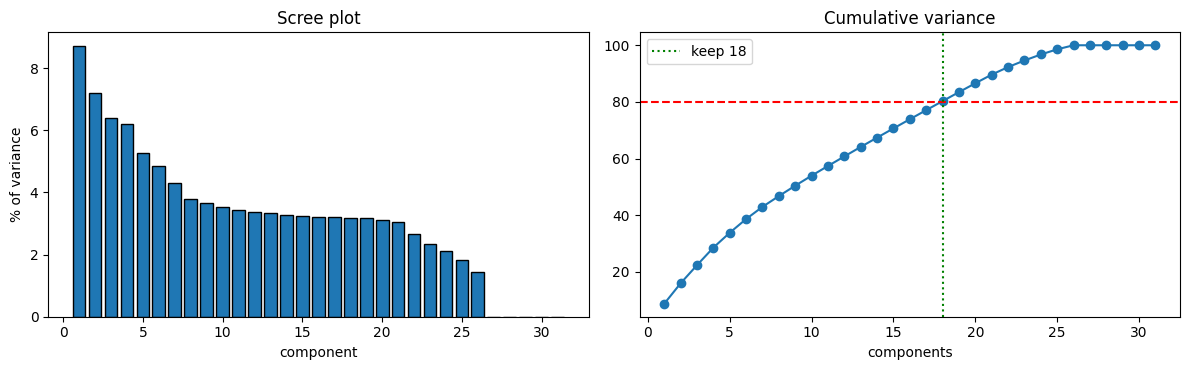

Columns in: 31   components kept: 18   variance explained: 80.3%
PC1 explains 8.7%, PC2 explains 7.2%


In [23]:
pca = PCA(random_state=SEED).fit(X3s)
ev = pca.explained_variance_ratio_
cum = np.cumsum(ev)
n_keep = int(np.argmax(cum >= 0.80) + 1)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].bar(range(1, len(ev) + 1), ev * 100, edgecolor='black'); ax[0].set_title('Scree plot'); ax[0].set_xlabel('component')
ax[0].set_ylabel('% of variance')
ax[1].plot(range(1, len(cum) + 1), cum * 100, 'o-'); ax[1].axhline(80, color='red', ls='--')
ax[1].axvline(n_keep, color='green', ls=':', label=f'keep {n_keep}'); ax[1].set_title('Cumulative variance')
ax[1].set_xlabel('components'); ax[1].legend()
plt.tight_layout(); plt.show()
print(f'Columns in: {X3.shape[1]}   components kept: {n_keep}   variance explained: {cum[n_keep - 1]:.1%}')
print(f'PC1 explains {ev[0]:.1%}, PC2 explains {ev[1]:.1%}')

## 3.6 What do PC1 and PC2 mean? (loadings)

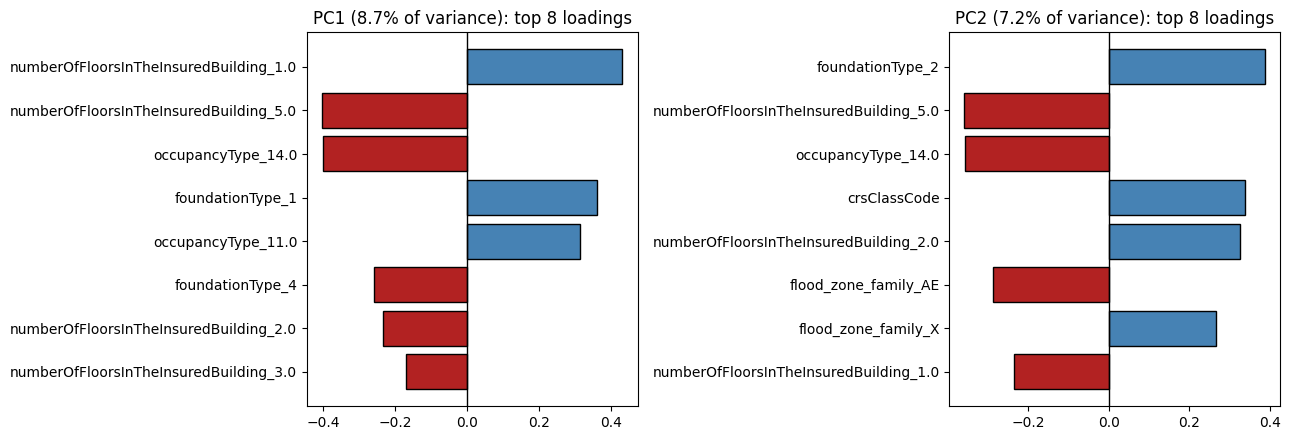

PC1 largest loadings: {'numberOfFloorsInTheInsuredBuilding_1.0': 0.43, 'numberOfFloorsInTheInsuredBuilding_5.0': -0.4, 'occupancyType_14.0': -0.4, 'foundationType_1': 0.36, 'occupancyType_11.0': 0.32}
PC2 largest loadings: {'foundationType_2': 0.39, 'numberOfFloorsInTheInsuredBuilding_5.0': -0.36, 'occupancyType_14.0': -0.35, 'crsClassCode': 0.34, 'numberOfFloorsInTheInsuredBuilding_2.0': 0.32}


In [24]:
loadings = pd.DataFrame(pca.components_[:2].T, index=X3.columns, columns=['PC1', 'PC2'])
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, pc in zip(ax, ['PC1', 'PC2']):
    top = loadings[pc].reindex(loadings[pc].abs().sort_values(ascending=False).index).head(8)[::-1]
    a.barh(top.index, top.values, color=['firebrick' if v < 0 else 'steelblue' for v in top.values], edgecolor='black')
    a.axvline(0, color='black', lw=1); a.set_title(f'{pc} ({ev[int(pc[-1]) - 1]:.1%} of variance): top 8 loadings')
plt.tight_layout(); plt.show()
for pc in ['PC1', 'PC2']:
    top = loadings[pc].reindex(loadings[pc].abs().sort_values(ascending=False).index).head(5)
    print(pc, 'largest loadings:', top.round(2).to_dict())

**What the components mean**
- **PC1 (8.7%)**: positive = one-floor, slab, single-family house; negative = mobile home on an elevated foundation.
  We read it as **"ordinary ground-level house vs mobile home"**.
- **PC2 (7.2%)**: positive = basement, two floors, higher CRS class (less flood protection credit), X zone;
  negative = mobile home, AE zone, one floor. We read it as **"inland basement homes vs homes in the high-risk AE zone"**.

Each component explains less than 9%. The variance is spread over many components because most of our columns are one-hot (0/1).
We needed **18 of 31** components to reach 80%.

## 3.7 Answer RQ3 with the reduced data, and compare

                              columns used  silhouette
K-means, all encoded columns            31       0.251
K-means, 18 PCA components              18       0.268

Agreement between the two clusterings (ARI): 0.291


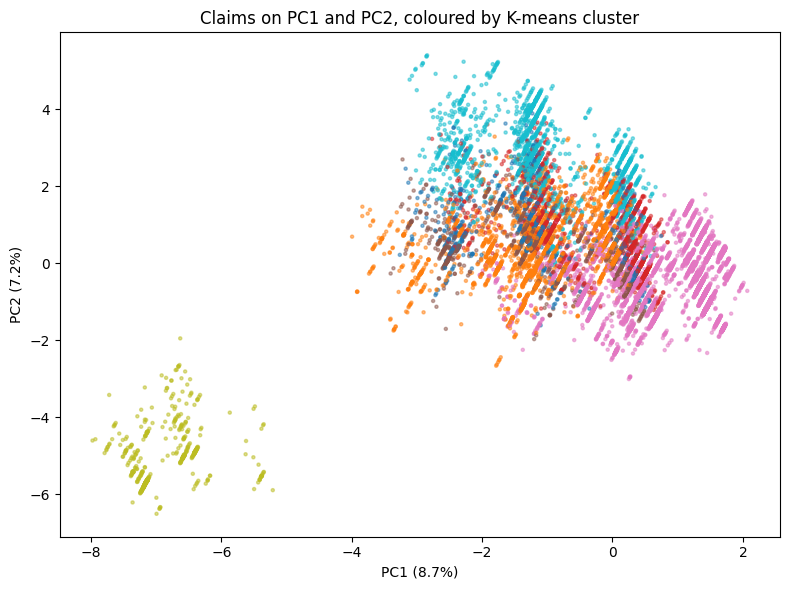

In [25]:
Zp = pca.transform(X3s)[:, :n_keep]
km_pca = KMeans(n_clusters=best_k, n_init=10, random_state=SEED).fit(Zp)
compare3 = pd.DataFrame({
    'columns used': [X3.shape[1], n_keep],
    'silhouette': [silhouette_score(X3s, kmeans.labels_, sample_size=5000, random_state=SEED),
                   silhouette_score(Zp, km_pca.labels_, sample_size=5000, random_state=SEED)],
}, index=['K-means, all encoded columns', f'K-means, {n_keep} PCA components'])
print(compare3.round(3))
print()
print(f"Agreement between the two clusterings (ARI): {adjusted_rand_score(kmeans.labels_, km_pca.labels_):.3f}")

plt.figure(figsize=(8, 6))
plt.scatter(Zp[:, 0], Zp[:, 1], c=kmeans.labels_, cmap='tab10', s=5, alpha=0.5)
plt.xlabel(f'PC1 ({ev[0]:.1%})'); plt.ylabel(f'PC2 ({ev[1]:.1%})')
plt.title('Claims on PC1 and PC2, coloured by K-means cluster')
plt.tight_layout(); plt.show()

## 3.8 Answer to RQ3

| | Columns | Silhouette | Agreement with K-means on all columns (ARI) |
|---|---|---|---|
| K-means, all encoded columns | 31 | 0.251 | - |
| Hierarchical (Ward), same k | 31 | 0.192 | 0.367 |
| K-means on PCA components | 18 | 0.268 | 0.291 |

**Answer in plain words.** Yes. Claims form **7 groups** that mostly follow **how the building stands on the ground**
(slab, crawlspace, basement, elevated, mobile home) and its age. The groups differ a lot in outcomes they never saw:
slab homes are about **4 times** more likely to be high severity than elevated homes.

- **How strong is the link to severity?** Cramér's V between cluster and high severity is **0.24**. The foundation code alone gives
  0.26, so the clusters mainly rediscover foundation type; flood zone and foundation together give 0.32.
- **K-means vs hierarchical:** K-means gave tighter groups (silhouette 0.26 vs 0.19). The two methods agree only partly (ARI 0.37).
- **PCA:** clustering on 18 components instead of 31 columns gave a slightly better silhouette (0.27 vs 0.25),
  but the groups changed a lot (ARI 0.29) and are harder to name. **Reducing helped a little with separation, and hurt interpretation.**
  We keep the clusters from the original columns for our answer.

**What this does not show.** A silhouette near 0.25 means the groups **overlap**. They are tendencies, not sharp boxes.
The best silhouette was actually at k = 2 (0.46), but two groups ("slab vs not slab") are too rough; we chose our rule before looking.
The groups mostly follow foundation type, because one-hot columns dominate the distances.

---
# Section 4: Summary

## Our three answers

1. **RQ1 (can we predict the dollar amount paid?)** On a **new storm**, only a little: the best model explains about **18%**
   of the dollar differences in building payments (2024-25). On storms the model has already seen (random split), about **59%**.
   The facts describe payments well, but predicting a new storm needs data about the storm itself.
2. **RQ2 (is it high severity?)** A decision tree finds **about 7 in 10** high-severity claims, with false alarms on about
   1 in 4 other claims. Coverage, location, how fast the claim is reported and building age matter most.
3. **RQ3 (are there risk profiles?)** Yes, **7 building profiles**. Ground-level slab homes have about 4 times
   more severe claims than elevated homes. This is a clear message for flood mitigation (elevating buildings).

## Limitations: what our results do NOT show
- **Florida and hurricanes dominate.** 55% of claims are in Florida, and a few storms create most claims. Results may not hold elsewhere.
- **Test years were unusual.** Helene and Milton (2024) were extreme; severe claims doubled. Scores on another period could differ.
- **Fills used all years.** In notebook 03, missing values and the high-severity cut-off were computed on all years, not only training years.
  This is a small leak; a stricter version would fit them on 2020-2023 only.
- **Samples.** Cross validation used 40,000 training claims and clustering used 20,000 claims, to keep run times short.
- **Clustering mixed 0/1 and numeric columns** with standard scaling. A distance made for mixed data might find different groups.
- **2025 is incomplete.** Many 2025 claims were not in the data yet.

## What we got wrong (and fixed)
- **First clustering run:** one cluster was simply "legacy policies", and PC1 measured the old vs new coding system.
  The cause: FEMA uses different occupancy and foundation codes before and after 2021. We added a check (Section 3.0),
  translated the old codes, and removed claims with no recorded foundation.
- **Cross validation was too optimistic** for both RQ1 and RQ2. Only the test on new years showed the real performance.
- **RQ1 was first scored on the log scale**, but the question asks for dollars. On the dollar scale the new-storm result is weaker
  (R² 0.18 instead of 0.32), and coordinates turned out to hurt. We now report dollars first.
- **Earlier claims in our EDA** (for example "latitude is missing at random") were wrong. Adding computed checks showed the real pattern.